In [21]:
import re
import numpy as np
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import ticker

In [22]:
def parse_comm_matrix(s: str):
    start_scan = False
    items = []
    for line in s.splitlines():
        if start_scan:
            if line.startswith('    '):
                if 'W0' not in line:
                    items.append(list(map(int, re.split(r'\s+', line.strip())[1:])))
            else:
                start_scan = False
        if 'Shared dependency:' in line:
            start_scan = True
    return np.array(items)

In [28]:
files = Path('build').glob('*.T*/build.ref.log')
def to_threads(x):
    return int(x.parent.suffix[2:])
files = sorted(files, key=to_threads)
x, d, v = [], [], []
for file in files:
    num_th = to_threads(file)
    if num_th > 1:
        mat = parse_comm_matrix(file.read_text())
        if mat.shape[0] > 0:
            x.append(num_th)
            d.append((mat != 0).sum() / (mat.shape[0] * (mat.shape[0] - 1)))
            v.append(mat.sum())
x, d, v = map(np.array, (x, d, v))

In [29]:
from sklearn.linear_model import LinearRegression
model = LinearRegression().fit(np.log(x[:, None]), np.log(d * x * x))
k = model.coef_[0]
b = model.intercept_
score = model.score(np.log(x[:, None]), np.log(d * x * x))
print(k, b)
print(model.score(np.log(x[:, None]), np.log(d * x * x)))

1.830560618104279 0.1946536283037732
0.991917400358993


In [30]:
print(','.join(list(map(str, d))))

1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.75,0.9166666666666666,1.0,1.0,0.95,1.0,1.0,1.0,1.0,0.9666666666666667,1.0,0.9666666666666667,1.0,1.0,0.9,0.7666666666666667,0.9047619047619048,0.9285714285714286,0.9761904761904762,1.0,0.8333333333333334,1.0,0.7619047619047619,0.7678571428571429,0.7678571428571429,0.6785714285714286,0.7142857142857143,0.9107142857142857,0.7678571428571429,1.0,0.8555555555555555,0.8,0.8888888888888888,1.0,0.7888888888888889,0.8333333333333334,0.7777777777777778,0.9166666666666666,0.8560606060606061,0.6515151515151515,0.7803030303030303,0.7575757575757576,1.0,0.7651515151515151,0.7967032967032966,0.978021978021978,0.6648351648351648,0.8736263736263736,0.6758241758241759,0.9010989010989011,0.6868131868131868,0.7875,0.7791666666666667,0.9375,0.5583333333333333,0.9916666666666667,0.775,0.7958333333333333,0.5973684210526315,0.6789473684210526,0.8,0.9710526315789474,0.7342105263157894,0.5710526315789474,0.6631578947368421,0.

In [31]:
print(','.join(list(map(str, x))))


2,2,2,2,2,2,2,3,3,3,3,3,3,3,3,4,4,4,4,4,4,4,4,5,5,5,5,5,5,5,6,6,6,6,6,6,6,7,7,7,7,7,7,7,8,8,8,8,8,8,8,10,10,10,10,10,10,10,12,12,12,12,12,12,12,14,14,14,14,14,14,14,16,16,16,16,16,16,16,20,20,20,20,20,20,20,24,24,24,24,24,24,24,28,28,28,28,28,28,28,32,32,32,32,32,32,32


Text(0, 0.5, '# Thread Sync Pair')

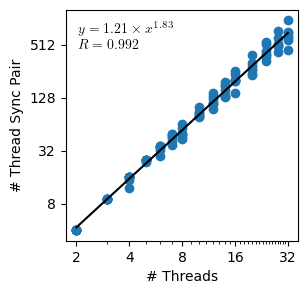

In [32]:
plt.figure(figsize=(3,3))
plt.scatter(x, d * x * x)
reg_x = np.exp(np.linspace(np.log(x.min()), np.log(x.max()), 100))
reg_y = np.exp(b) * reg_x ** k
plt.plot(reg_x, reg_y, color='k', lw=1.5)
plt.xscale('log')
plt.yscale('log')
plt.gca().xaxis.set_major_locator(ticker.LogLocator(2))
plt.gca().xaxis.set_minor_locator(ticker.IndexLocator(1, 1))
plt.gca().xaxis.set_major_formatter(ticker.LogFormatter(2))
plt.gca().xaxis.set_minor_formatter(ticker.NullFormatter())
plt.gca().yaxis.set_major_locator(ticker.LogLocator(2))
plt.gca().yaxis.set_minor_locator(ticker.NullLocator())
plt.gca().yaxis.set_major_formatter(ticker.LogFormatter(2))
plt.gca().yaxis.set_minor_formatter(ticker.NullFormatter())
plt.gcf().text(0.05, 0.9, rf'$y={np.exp(b):.3} \times x ^ {{{k:.3}}}$', transform=plt.gca().transAxes, usetex=True)
plt.gcf().text(0.05, 0.83, rf'$R={score:.3}$', transform=plt.gca().transAxes, usetex=True)
plt.xlabel('# Threads')
plt.ylabel('# Thread Sync Pair')
# plt.ylabel('# Thread synchronization')
# plt.twinx().scatter(x, v, color='b')
# plt.yscale('log')
# sns.despine(right=False)
